# Шаг 0
---

In [1]:
!nvidia-smi

Thu Oct 22 12:33:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import numba
import numpy as np
from numba import cuda

print("numba:", numba.__version__)
print("CUDA доступна:", cuda.is_available())

if cuda.is_available():
    dev = cuda.get_current_device()
    print("Видеокарта:", dev.name.decode() if isinstance(dev.name, bytes) else dev.name)
    print("Количество SM:", dev.MULTIPROCESSOR_COUNT)
    print("Размер warp:", dev.WARP_SIZE)

numba: 0.61.2
CUDA доступна: True
Видеокарта: Tesla T4
Количество SM: 40
Размер warp: 32


# Шаг 1
---

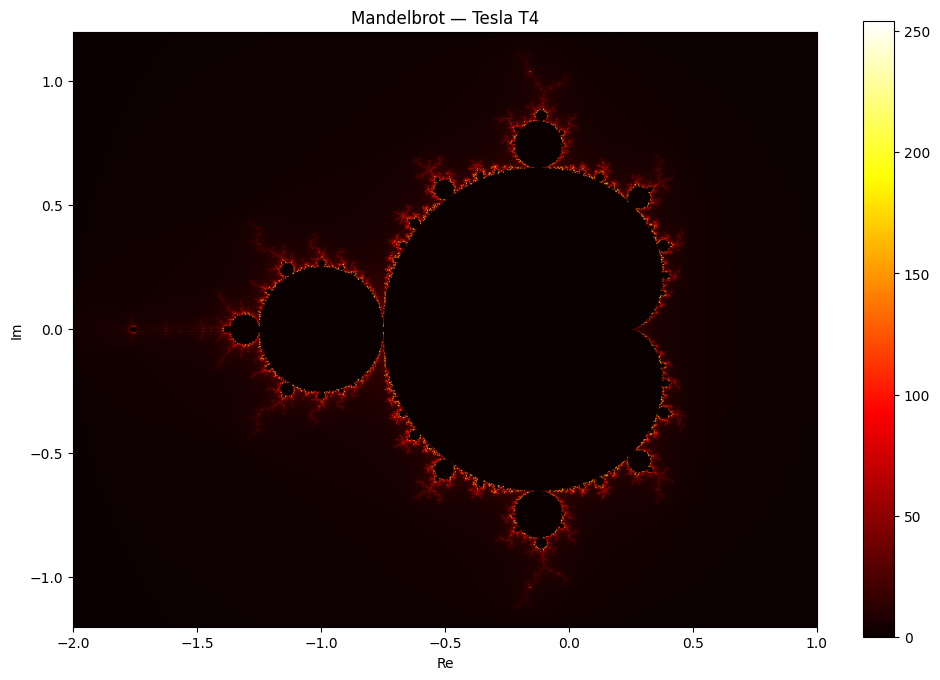

Размер изображения: (800, 1200)
Количество пикселей: 960000
Количество блоков: (75, 50)
Результат получен: int32


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from numba import cuda

# Размер изображения
W = 1200
H = 800
MAX_ITER = 300

# Границы координат
XMIN, XMAX = -2.0, 1.0
YMIN, YMAX = -1.2, 1.2


@cuda.jit(fastmath=False)
def mandelbrot_gpu(out, xmin, xmax, ymin, ymax, max_iter):
    x, y = cuda.grid(2)

    if x < out.shape[1] and y < out.shape[0]:
        real = xmin + x * (xmax - xmin) / out.shape[1]
        imag = ymin + y * (ymax - ymin) / out.shape[0]

        zr = 0.0
        zi = 0.0
        iteration = 0

        while zr * zr + zi * zi <= 4.0 and iteration < max_iter:
            # (zr + zi*i)^2 + (real + imag*i)
            new_zr = zr * zr - zi * zi + real
            new_zi = 2.0 * zr * zi + imag

            zr = new_zr
            zi = new_zi
            iteration += 1

        if iteration == max_iter:
            out[y, x] = 0
        else:
            out[y, x] = int(255 * iteration / max_iter)


# Выделяем память на GPU
d_out = cuda.device_array((H, W), dtype=np.int32)

# Размер блока: 16 × 16 = 256 потоков
threads_per_block = (16, 16)

# Считаем количество блоков по каждой оси
blocks_per_grid = (
    (W + threads_per_block[0] - 1) // threads_per_block[0],
    (H + threads_per_block[1] - 1) // threads_per_block[1]
)

# Запускаем ядро
mandelbrot_gpu[blocks_per_grid, threads_per_block](
    d_out, XMIN, XMAX, YMIN, YMAX, MAX_ITER
)

# Копируем результат обратно на CPU
out = d_out.copy_to_host()

# Показываем изображение
plt.figure(figsize=(12, 8))
plt.imshow(out, cmap="hot", extent=[XMIN, XMAX, YMIN, YMAX])
plt.title("Mandelbrot — Tesla T4")
plt.xlabel("Re")
plt.ylabel("Im")
plt.colorbar()
plt.show()

print("Размер изображения:", out.shape)
print("Количество пикселей:", out.size)
print("Количество блоков:", blocks_per_grid)
print("Результат получен:", out.dtype)

# Шаг 2
---

In [15]:
from numba import njit, prange
import numpy as np

@njit(parallel=True)
def mandelbrot_cpu(width, height, xmin, xmax, ymin, ymax, max_iter):
    out = np.empty((height, width), dtype=np.int32)

    for y in prange(height):
        for x in range(width):
            real = xmin + x * (xmax - xmin) / width
            imag = ymin + y * (ymax - ymin) / height

            zr = 0.0
            zi = 0.0
            iteration = 0

            while zr * zr + zi * zi <= 4.0 and iteration < max_iter:
                new_zr = zr * zr - zi * zi + real
                new_zi = 2.0 * zr * zi + imag

                zr = new_zr
                zi = new_zi
                iteration += 1

            if iteration == max_iter:
                out[y, x] = 0
            else:
                out[y, x] = int(255 * iteration / max_iter)

    return out


cpu_out = mandelbrot_cpu(
    W, H, XMIN, XMAX, YMIN, YMAX, MAX_ITER
)

differences = np.count_nonzero(out != cpu_out)

print("Несовпадающих пикселей:", differences)
print("Всего пикселей:", out.size)
print("Результаты совпадают:", differences == 0)

ys, xs = np.where(out != cpu_out)

for y, x in zip(ys, xs):
    print(f"Пиксель ({x}, {y}): GPU={out[y, x]}, CPU={cpu_out[y, x]}")

    real = XMIN + x * (XMAX - XMIN) / W
    imag = YMIN + y * (YMAX - YMIN) / H

    print(f"  Координаты: real={real}, imag={imag}")

Несовпадающих пикселей: 2
Всего пикселей: 960000
Результаты совпадают: False
Пиксель (945, 281): GPU=248, CPU=0
  Координаты: real=0.3624999999999998, imag=-0.357
Пиксель (945, 519): GPU=248, CPU=0
  Координаты: real=0.3624999999999998, imag=0.357


In [16]:
@cuda.jit
def check_points_gpu(points, result, max_iter):
    i = cuda.grid(1)

    if i < points.shape[0]:
        real = points[i, 0]
        imag = points[i, 1]

        zr = 0.0
        zi = 0.0
        iteration = 0

        while zr * zr + zi * zi <= 4.0 and iteration < max_iter:
            new_zr = zr * zr - zi * zi + real
            new_zi = 2.0 * zr * zi + imag
            zr = new_zr
            zi = new_zi
            iteration += 1

        result[i] = iteration


points = np.array([
    [XMIN + 945 * (XMAX - XMIN) / W, YMIN + 281 * (YMAX - YMIN) / H],
    [XMIN + 945 * (XMAX - XMIN) / W, YMIN + 519 * (YMAX - YMIN) / H]
], dtype=np.float64)

d_points = cuda.to_device(points)
d_result = cuda.device_array(2, dtype=np.int32)

check_points_gpu[1, 32](d_points, d_result, 1000)
cuda.synchronize()

print("GPU, число итераций:", d_result.copy_to_host())


GPU, число итераций: [292 292]


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


In [17]:
@njit
def check_points_cpu(points, max_iter):
    result = np.empty(points.shape[0], dtype=np.int32)

    for i in range(points.shape[0]):
        real = points[i, 0]
        imag = points[i, 1]

        zr = 0.0
        zi = 0.0
        iteration = 0

        while zr * zr + zi * zi <= 4.0 and iteration < max_iter:
            new_zr = zr * zr - zi * zi + real
            new_zi = 2.0 * zr * zi + imag
            zr = new_zr
            zi = new_zi
            iteration += 1

        result[i] = iteration

    return result


print("CPU, число итераций:", check_points_cpu(points, 1000))

CPU, число итераций: [423 423]


In [18]:
for limit in [250, 300, 400, 500, 1000]:
    cpu_result = check_points_cpu(points, limit)

    gpu_result = cuda.device_array(2, dtype=np.int32)
    check_points_gpu[1, 32](
        d_points, gpu_result, limit
    )
    cuda.synchronize()
    gpu_result = gpu_result.copy_to_host()

    print(
        f"Лимит {limit}: "
        f"CPU={cpu_result.tolist()}, "
        f"GPU={gpu_result.tolist()}"
    )

Лимит 250: CPU=[250, 250], GPU=[250, 250]
Лимит 300: CPU=[300, 300], GPU=[292, 292]
Лимит 400: CPU=[400, 400], GPU=[292, 292]
Лимит 500: CPU=[423, 423], GPU=[292, 292]
Лимит 1000: CPU=[423, 423], GPU=[292, 292]


In [19]:
@cuda.jit(fastmath=False)
def check_points_gpu_test(points, result, max_iter):
    i = cuda.grid(1)

    if i < points.shape[0]:
        real = points[i, 0]
        imag = points[i, 1]

        zr = 0.0
        zi = 0.0
        iteration = 0

        while zr * zr + zi * zi <= 4.0 and iteration < max_iter:
            new_zr = zr * zr - zi * zi + real
            new_zi = 2.0 * zr * zi + imag

            zr = new_zr
            zi = new_zi
            iteration += 1

        result[i] = iteration


test_result = cuda.device_array(2, dtype=np.int32)

check_points_gpu_test[1, 32](
    d_points, test_result, 1000
)
cuda.synchronize()

print("GPU без fastmath:", test_result.copy_to_host())

GPU без fastmath: [292 292]


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


In [20]:
def check_complex(real, imag, max_iter):
    c = complex(real, imag)
    z = 0j
    iteration = 0

    while abs(z) <= 2 and iteration < max_iter:
        z = z * z + c
        iteration += 1

    return iteration


for i in range(2):
    real = float(points[i, 0])
    imag = float(points[i, 1])

    print(f"\nТочка {i + 1}")
    print("real:", repr(real))
    print("imag:", repr(imag))
    print("CPU с комплексными числами:", check_complex(real, imag, 1000))
    print("CPU с раздельными координатами:", check_points_cpu(points[i:i+1], 1000)[0])


Точка 1
real: 0.3624999999999998
imag: -0.357
CPU с комплексными числами: 423
CPU с раздельными координатами: 423

Точка 2
real: 0.3624999999999998
imag: 0.357
CPU с комплексными числами: 423
CPU с раздельными координатами: 423


In [24]:
print("GPU kernel:", mandelbrot_gpu)
print("CUDA доступна:", cuda.is_available())
print("Тип GPU-результата:", out.dtype)
print("Тип CPU-результата:", cpu_out.dtype)
print("Несовпадений:", np.count_nonzero(out != cpu_out))

GPU kernel: CUDADispatcher(<function mandelbrot_gpu at 0x7ec2a1d1bb00>)
CUDA доступна: True
Тип GPU-результата: int32
Тип CPU-результата: int32
Несовпадений: 2


# Шаг 3
---


In [25]:
import time
from numba import cuda
import numpy as np

def zamir_gpu(W, H, blok=(16, 16), n=3):
    host = np.empty((H, W), dtype=np.int32)

    threads = blok
    blocks = (
        (W + threads[0] - 1) // threads[0],
        (H + threads[1] - 1) // threads[1]
    )

    to_gpu_times = []
    kernel_times = []
    to_cpu_times = []

    for _ in range(n):
        # 1. Выделяем память и измеряем передачу пустого массива на GPU
        start = time.perf_counter()
        d_out = cuda.to_device(host)
        cuda.synchronize()
        to_gpu_times.append(time.perf_counter() - start)

        # 2. Измеряем только вычисление ядра
        cuda.synchronize()
        start = time.perf_counter()

        mandelbrot_gpu[blocks, threads](
            d_out, XMIN, XMAX, YMIN, YMAX, MAX_ITER
        )

        cuda.synchronize()
        kernel_times.append(time.perf_counter() - start)

        # 3. Измеряем копирование результата обратно
        start = time.perf_counter()
        result = d_out.copy_to_host()
        to_cpu_times.append(time.perf_counter() - start)

    return (
        min(to_gpu_times),
        min(kernel_times),
        min(to_cpu_times),
        result
    )


t_to_gpu, t_kernel, t_to_cpu, gpu_result = zamir_gpu(W, H)

print(f"Передача на GPU: {t_to_gpu * 1000:.3f} мс")
print(f"Выполнение ядра: {t_kernel * 1000:.3f} мс")
print(f"Копирование обратно: {t_to_cpu * 1000:.3f} мс")

total = t_to_gpu + t_kernel + t_to_cpu
print(f"Суммарное время: {total * 1000:.3f} мс")
print(f"Доля копирований: {(t_to_gpu + t_to_cpu) / total * 100:.1f}%")

Передача на GPU: 1.509 мс
Выполнение ядра: 15.821 мс
Копирование обратно: 1.206 мс
Суммарное время: 18.537 мс
Доля копирований: 14.6%


# Шаг 4
---

In [26]:
sizes = [
    (300, 200),
    (1200, 800),
    (3000, 2000)
]

results = []

for width, height in sizes:
    t_to_gpu, t_kernel, t_to_cpu, gpu_result = zamir_gpu(
        width, height
    )

    total = t_to_gpu + t_kernel + t_to_cpu
    copy_percent = (t_to_gpu + t_to_cpu) / total * 100

    results.append({
        "Размер": f"{width}x{height}",
        "Передача на GPU (мс)": round(t_to_gpu * 1000, 3),
        "Ядро (мс)": round(t_kernel * 1000, 3),
        "Копирование обратно (мс)": round(t_to_cpu * 1000, 3),
        "Всего (мс)": round(total * 1000, 3),
        "Доля копирований (%)": round(copy_percent, 1)
    })

import pandas as pd
display(pd.DataFrame(results))

,Размер,Передача на GPU (мс),Ядро (мс),Копирование обратно (мс),Всего (мс),Доля копирований (%)
0,300x200,1.006,2.183,0.218,3.407,35.9
1,1200x800,1.196,15.297,1.013,17.506,12.6
2,3000x2000,4.999,60.489,5.888,71.376,15.3


In [27]:
import time
import pandas as pd

cpu_results = []

for width, height in [(300, 200), (1200, 800), (3000, 2000)]:
    # Первый запуск может включать компиляцию,
    # поэтому прогреваем функцию отдельно.
    mandelbrot_cpu(
        width, height, XMIN, XMAX, YMIN, YMAX, MAX_ITER
    )

    times = []

    for _ in range(3):
        start = time.perf_counter()

        cpu_result = mandelbrot_cpu(
            width, height, XMIN, XMAX, YMIN, YMAX, MAX_ITER
        )

        times.append(time.perf_counter() - start)

    cpu_time = min(times)

    cpu_results.append({
        "Размер": f"{width}x{height}",
        "CPU njit parallel (мс)": round(cpu_time * 1000, 3)
    })

display(pd.DataFrame(cpu_results))

,Размер,CPU njit parallel (мс)
0,300x200,22.373
1,1200x800,163.200
2,3000x2000,1904.092


# Шаг 7.1
---


In [28]:
@cuda.jit
def mandelbrot_stride(out, xmin, xmax, ymin, ymax, max_iter):
    x, y = cuda.grid(2)

    # Шаг между потоками по каждой оси
    stride_x, stride_y = cuda.gridsize(2)

    # Один поток обрабатывает несколько пикселей
    for yy in range(y, out.shape[0], stride_y):
        for xx in range(x, out.shape[1], stride_x):
            real = xmin + xx * (xmax - xmin) / out.shape[1]
            imag = ymin + yy * (ymax - ymin) / out.shape[0]

            zr = 0.0
            zi = 0.0
            iteration = 0

            while zr * zr + zi * zi <= 4.0 and iteration < max_iter:
                new_zr = zr * zr - zi * zi + real
                new_zi = 2.0 * zr * zi + imag

                zr = new_zr
                zi = new_zi
                iteration += 1

            if iteration == max_iter:
                out[yy, xx] = 0
            else:
                out[yy, xx] = int(255 * iteration / max_iter)

# Шаг 7.2
---

In [29]:
import time
import pandas as pd
import numpy as np
from numba import cuda

threads = (16, 16)
k_values = [1, 2, 4, 8, 16]

stride_results = []

# Эталонный результат обычного GPU-ядра
d_reference = cuda.device_array((H, W), dtype=np.int32)

regular_blocks = (
    (W + threads[0] - 1) // threads[0],
    (H + threads[1] - 1) // threads[1]
)

mandelbrot_gpu[regular_blocks, threads](
    d_reference, XMIN, XMAX, YMIN, YMAX, MAX_ITER
)
cuda.synchronize()
reference = d_reference.copy_to_host()

for k in k_values:
    blocks = (40 * k, 4)
    d_out_stride = cuda.device_array((H, W), dtype=np.int32)

    # Прогрев перед замером
    mandelbrot_stride[blocks, threads](
        d_out_stride, XMIN, XMAX, YMIN, YMAX, MAX_ITER
    )
    cuda.synchronize()

    times = []

    for _ in range(3):
        cuda.synchronize()
        start = time.perf_counter()

        mandelbrot_stride[blocks, threads](
            d_out_stride, XMIN, XMAX, YMIN, YMAX, MAX_ITER
        )

        cuda.synchronize()
        times.append(time.perf_counter() - start)

    result = d_out_stride.copy_to_host()
    differences = np.count_nonzero(result != reference)

    stride_results.append({
        "k": k,
        "Блоки": f"{blocks[0]} × {blocks[1]}",
        "Потоков всего": blocks[0] * blocks[1] * threads[0] * threads[1],
        "Время ядра (мс)": round(min(times) * 1000, 3),
        "Несовпадающих пикселей": int(differences)
    })

display(pd.DataFrame(stride_results))

,k,Блоки,Потоков всего,Время ядра (мс),Несовпадающих пикселей
0,1,40 × 4,40960,21.531,0
1,2,80 × 4,81920,22.547,0
2,4,160 × 4,163840,8.539,0
3,8,320 × 4,327680,9.182,0
4,16,640 × 4,655360,8.771,0
